# Multi-Layer Perceptron: A Small Neural Network for Digits

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `digits` | **Runs on:** CPU, about 2 minute(s)

Stack linear layers with nonlinearities and train them with backpropagation.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How a hidden layer creates features
- How backpropagation computes gradients
- Why neural networks vary between random seeds
- How early stopping and L2 regularisation help

**Prerequisites:**

- Logistic regression notebook
- Chain rule of derivatives

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** Digit recognition is the classic test of neural networks.

**The problem.** Classify 8 by 8 digit images with a one hidden layer network.

**Why it matters.** The same building blocks scale to deep networks for images and text.

**Why machine learning.** Features are learned, not designed.

**Why this algorithm.** A small MLP is the simplest neural network that is nonlinear.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### The Elements of Statistical Learning (2nd ed.)

- **Type:** foundational paper
- **Authors:** Hastie, T., Tibshirani, R. and Friedman, J.
- **Year and venue:** 2009, Springer
- **DOI or URL:** https://doi.org/10.1007/978-0-387-84858-7
- **Verification:** not verified in build environment
- **Research objective:** Textbook on statistical learning.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text.
- **Limitations:** Textbook.

### Why do tree-based models still outperform deep learning on tabular data?

- **Type:** modern paper
- **Authors:** Grinsztajn, L., Oyallon, E. and Varoquaux, G.
- **Year and venue:** 2022, NeurIPS 2022 Datasets and Benchmarks; arXiv:2207.08815
- **DOI or URL:** https://arxiv.org/abs/2207.08815
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Benchmark tree models against neural networks on medium sized tabular data.
- **Methodology:** Large benchmark with random search budgets over 45 datasets as described in the paper.
- **Dataset:** Tabular benchmark collected from OpenML and other public sources.
- **Main findings:** Tree ensembles stayed ahead of the deep models on the studied datasets.
- **Limitations:** Medium sized data only, no very large datasets.

**Relationship to this notebook.** Hastie et al. cover neural networks and backpropagation. Grinsztajn et al. found tree models stronger than neural networks on tabular data, but our data are images, where neural networks are usually strong. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Forward pass.** $h = \max(0, W_1 x + b_1)$, $z = W_2 h + b_2$, $p = \operatorname{softmax}(z)$.

**Loss.** Cross entropy $\ell = -\sum_k y_k \log p_k$ plus an L2 term $\tfrac{\alpha}{2}\lVert W \rVert^2$.

**Backpropagation.** $\partial\ell/\partial z = p - y$, $\partial\ell/\partial W_2 = h^\top (p-y)$, then $\partial\ell/\partial h = (p-y) W_2^\top$ and $\partial\ell/\partial z_1 = \partial\ell/\partial h \odot \mathbb{1}[z_1 > 0]$.

**Optimisation.** Gradient descent variants (Adam in scikit-learn). The loss is non convex, so results depend on the seed.

**Limitations.** Needs scaling, many hyperparameters, no guarantee of the global optimum.

## 5. Dataset Introduction

**Optical Recognition of Handwritten Digits**, UCI, licence CC BY 4.0, DOI 10.24432/C50P49. scikit-learn ships 1797 images (the test part of the UCI data) as 8 by 8 grids, so 64 integer pixel features from 0 to 16. Target `digit`, ten classes. Limit: far smaller than MNIST.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "mlp"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("digits")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: classification | target: digit | shape: (1797, 65)


,source
title,Optical Recognition of Handwritten Digits
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/80/optical...
license,CC BY 4.0
doi,10.24432/C50P49
rows,1797
features,64
limits,"8x8 images, much smaller than MNIST."


,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7,digit
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (1797, 65)


,columns by dtype
float64,64
int64,1


,count,mean,std,min,25%,50%,75%,max
pixel_0_0,1797.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
pixel_0_1,1797.0,0.304,0.907,0.0,0.0,0.0,0.0,8.0
pixel_0_2,1797.0,5.205,4.755,0.0,1.0,4.0,9.0,16.0
pixel_0_3,1797.0,11.836,4.249,0.0,10.0,13.0,15.0,16.0
pixel_0_4,1797.0,11.848,4.287,0.0,10.0,13.0,15.0,16.0
pixel_0_5,1797.0,5.782,5.666,0.0,0.0,4.0,11.0,16.0
pixel_0_6,1797.0,1.362,3.326,0.0,0.0,0.0,0.0,16.0
pixel_0_7,1797.0,0.130,1.037,0.0,0.0,0.0,0.0,15.0
pixel_1_0,1797.0,0.006,0.094,0.0,0.0,0.0,0.0,2.0
pixel_1_1,1797.0,1.994,3.196,0.0,0.0,0.0,3.0,16.0


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


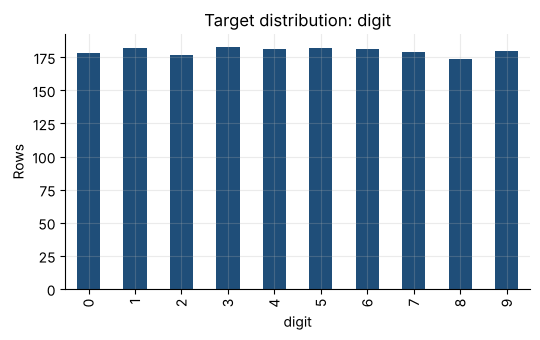

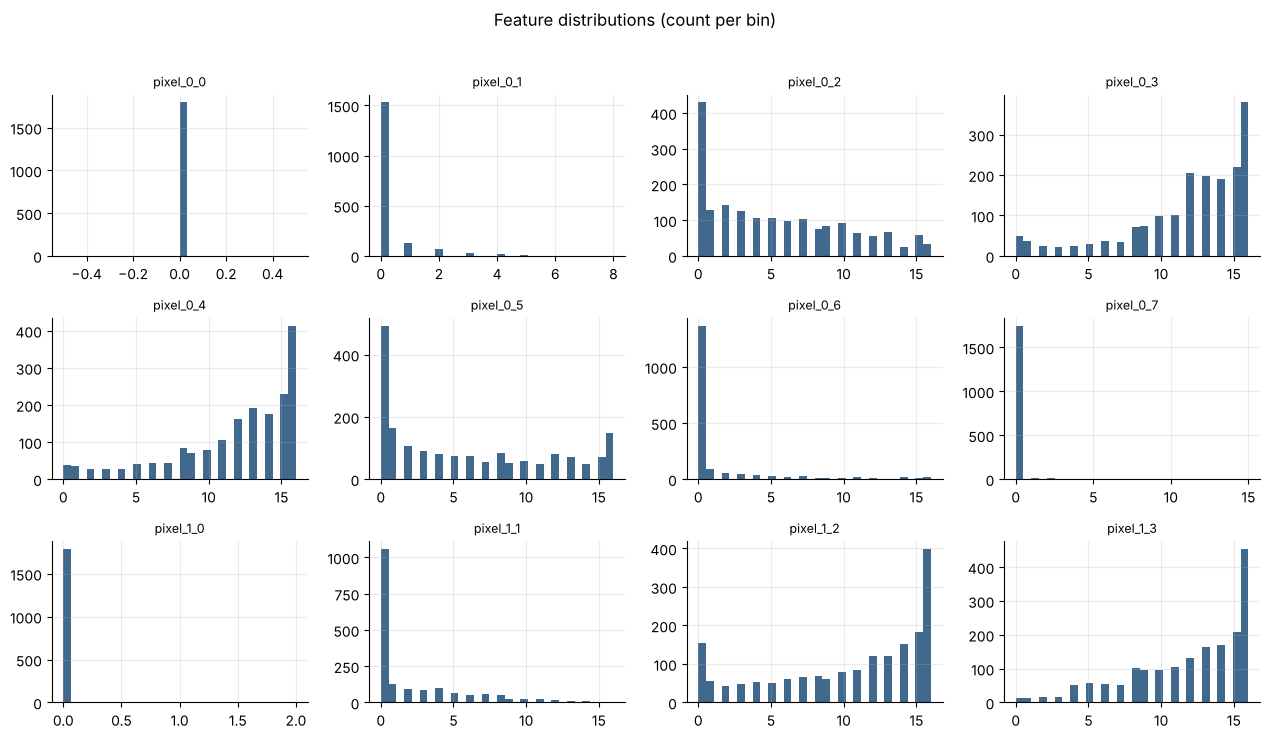

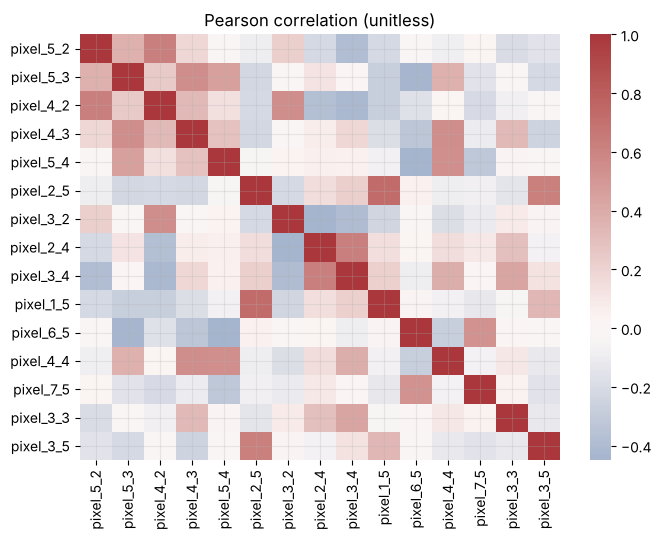

,feature,outliers,percent
0,pixel_0_6,428,23.82
1,pixel_6_1,421,23.43
2,pixel_7_6,267,14.86
3,pixel_0_1,266,14.80
4,pixel_1_6,237,13.19
5,pixel_7_1,219,12.19
6,pixel_5_1,181,10.07
7,pixel_1_1,156,8.68


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=True, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 1077 360 360


,train,validation,test
digit,,,
0,0.098,0.100,0.100
1,0.101,0.103,0.100
2,0.099,0.097,0.097
3,0.101,0.103,0.103
4,0.101,0.100,0.100
5,0.101,0.100,0.103
6,0.101,0.100,0.100
7,0.099,0.100,0.100
8,0.097,0.097,0.097


transformed train shape: (1077, 64)


## 8. Algorithm Implementation

### 8.1 Concept

The hidden layer learns stroke like detectors. The output layer combines them into class scores.

### 8.2 Python implementation from scratch

We train a one hidden layer network with full batch gradient descent in NumPy.

validation accuracy, scratch network: 0.9778


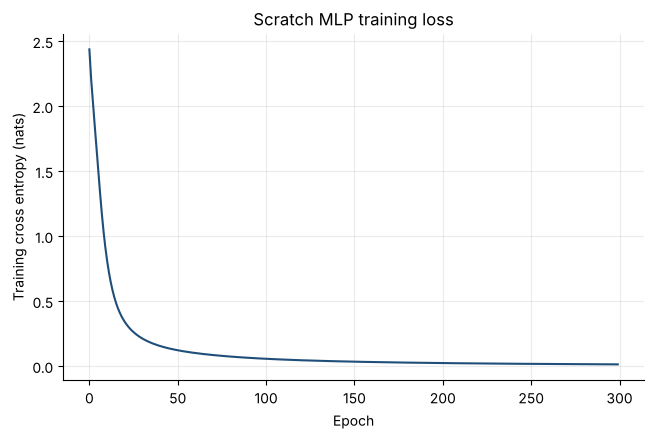

In [6]:
ytr, yva = y_train.values, y_val.values
K, hidden = 10, 32
Y = np.eye(K)[ytr]
rng = np.random.default_rng(SEED)
W1, b1 = rng.normal(0, 0.1, (Xtr.shape[1], hidden)), np.zeros(hidden)
W2, b2 = rng.normal(0, 0.1, (hidden, K)), np.zeros(K)
losses = []
for epoch in range(300):
    Z1 = Xtr @ W1 + b1
    A1 = np.maximum(0, Z1)
    Z2 = A1 @ W2 + b2
    P = np.exp(Z2 - Z2.max(axis=1, keepdims=True)); P /= P.sum(axis=1, keepdims=True)
    losses.append(-np.mean(np.log(P[np.arange(len(ytr)), ytr] + 1e-12)))
    dZ2 = (P - Y) / len(ytr)
    dW2, db2 = A1.T @ dZ2, dZ2.sum(axis=0)
    dZ1 = (dZ2 @ W2.T) * (Z1 > 0)
    dW1, db1 = Xtr.T @ dZ1, dZ1.sum(axis=0)
    W1 -= 0.5 * dW1; b1 -= 0.5 * db1; W2 -= 0.5 * dW2; b2 -= 0.5 * db2
pred = (np.maximum(0, Xva @ W1 + b1) @ W2 + b2).argmax(axis=1)
print("validation accuracy, scratch network:", round(float(np.mean(pred == yva)), 4))
plt.plot(losses); plt.xlabel("Epoch"); plt.ylabel("Training cross entropy (nats)"); plt.title("Scratch MLP training loss"); plt.show()

### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `hidden_layer_sizes` | Units per hidden layer. |
| `alpha` | L2 penalty. |
| `learning_rate_init` | Adam step size. |
| `early_stopping` | Hold out data to stop training. |
| `max_iter` | Epoch limit. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "F1"
LOWER_IS_BETTER = False
SCORING = "f1_macro"
SWEEP_PARAM = "model__hidden_layer_sizes"
SWEEP_VALUES = [(8,), (16,), (32,), (64,), (128,)]

def build_pipeline():
    return make_model_pipeline(X_train, MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=500, early_stopping=True, random_state=SEED), scale=True, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

MLPClassifier(alpha=0.001, early_stopping=True, hidden_layer_sizes=(64,),
              max_iter=500, random_state=42)


,F1,Accuracy,F1
model__hidden_layer_sizes,,,
"(8,)",0.8955,0.8972,0.8955
"(16,)",0.8556,0.8611,0.8556
"(32,)",0.9437,0.9444,0.9437
"(64,)",0.9470,0.9472,0.9470
"(128,)",0.9583,0.9583,0.9583


best model__hidden_layer_sizes on validation: (128,)


refit on train plus validation rows


## 10. Evaluation

Classification metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC, plus the confusion matrix. With imbalanced classes accuracy alone misleads, so the model is chosen on F1 or PR-AUC as stated in the training cell.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "MLPClassifier": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="MLPClassifier", dataset="digits",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,Accuracy,Precision,Recall,F1,ROC_AUC_ovr
baseline,0.1000,0.0100,0.1000,0.0182,0.5000
MLPClassifier,0.9611,0.9626,0.9609,0.9607,0.9972


5-fold CV f1_macro: mean 0.9446, std 0.0156
saved mlp.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

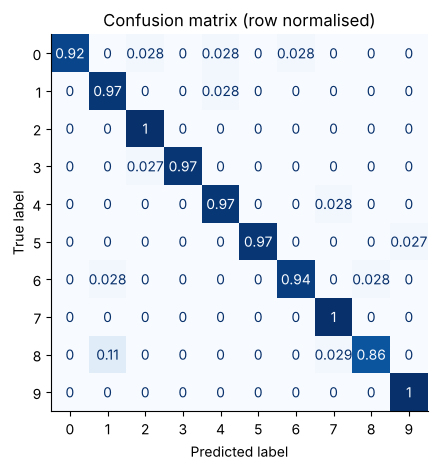

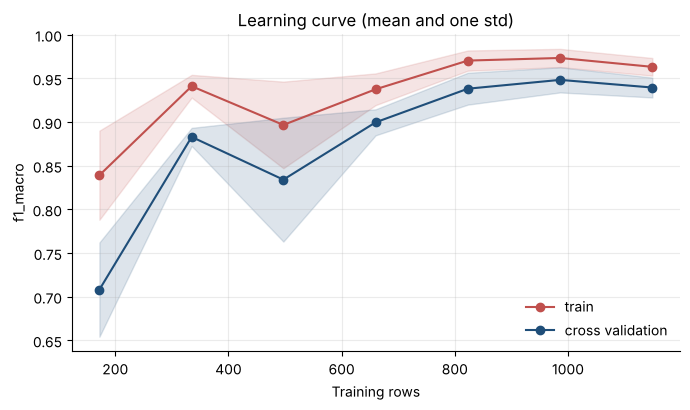

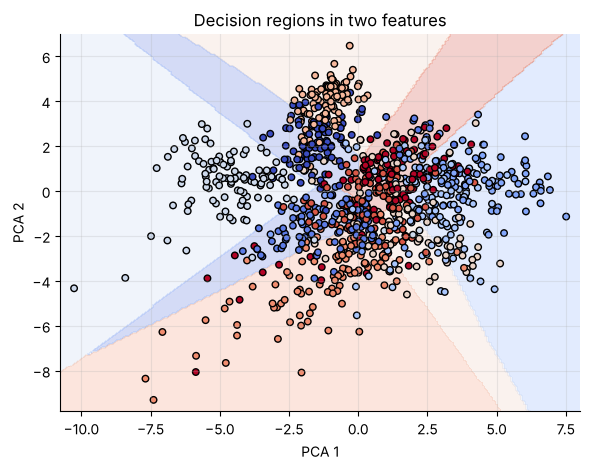

In [9]:
pred = final_model.predict(X_test)
labels = bundle.target_names or None
fig = viz.plot_confusion(y_test, pred, labels=labels)
save_figure(fig, NOTEBOOK_ID, "confusion"); plt.show()
if y_test.nunique() == 2:
    fig = viz.plot_roc_pr(final_model, X_test, y_test)
    save_figure(fig, NOTEBOOK_ID, "roc_pr"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()
# decision regions in two PCA axes
pca_view = PCA(n_components=2, random_state=SEED).fit(Xtr)
model_for_plot = clone(final_model.named_steps["model"])
fig = viz.plot_decision_boundary(lambda: clone(model_for_plot), pca_view.transform(Xtr), y_train.values,
                                 names=["PCA 1", "PCA 2"])
save_figure(fig, NOTEBOOK_ID, "decision_regions"); plt.show()

## 12. Interpretation

Permutation importance shows which inputs the model relies on. The confusion matrix shows which classes are mixed up, and the list of misclassified rows is the starting point for error analysis. A model is only as good as the cases it fails on.

In [10]:
print("Permutation importance is skipped: the features are raw pixels, so single pixel importance is not meaningful.")
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

Permutation importance is skipped: the features are raw pixels, so single pixel importance is not meaningful.
Misclassified test rows: 14 of 360

Test F1: 0.9607 | baseline F1: 0.0182
Cross validation spread (std): 0.0156. A test gap larger than this spread is meaningful.


## 13. Experiments and Challenges

### Experiment 1: Seed variability

Train the same network with five seeds and report the spread of validation accuracy.

In [11]:
accs = []
for seed in range(5):
    m = MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=500, early_stopping=True, random_state=seed).fit(Xtr, y_train)
    accs.append(m.score(Xva, y_val))
print("validation accuracy by seed:", np.round(accs, 4), "| mean", round(float(np.mean(accs)), 4), "| std", round(float(np.std(accs, ddof=1)), 4))

validation accuracy by seed: [0.9083 0.9056 0.9694 0.8944 0.9528] | mean 0.9261 | std 0.0329


### Experiment 2: Regularisation strength

Vary the L2 penalty.

In [12]:
for alpha in [1e-6, 1e-3, 1e-1, 1.0, 3.0]:
    m = MLPClassifier(hidden_layer_sizes=(64,), alpha=alpha, max_iter=500, random_state=SEED).fit(Xtr, y_train)
    print(f"alpha={alpha}: train accuracy {m.score(Xtr, y_train):.3f}, validation accuracy {m.score(Xva, y_val):.3f}")

alpha=1e-06: train accuracy 1.000, validation accuracy 0.975


alpha=0.001: train accuracy 1.000, validation accuracy 0.975


alpha=0.1: train accuracy 1.000, validation accuracy 0.978


alpha=1.0: train accuracy 0.999, validation accuracy 0.981


alpha=3.0: train accuracy 0.993, validation accuracy 0.975


### Experiment 3: Learning curve of the loss

Plot the loss recorded during training.

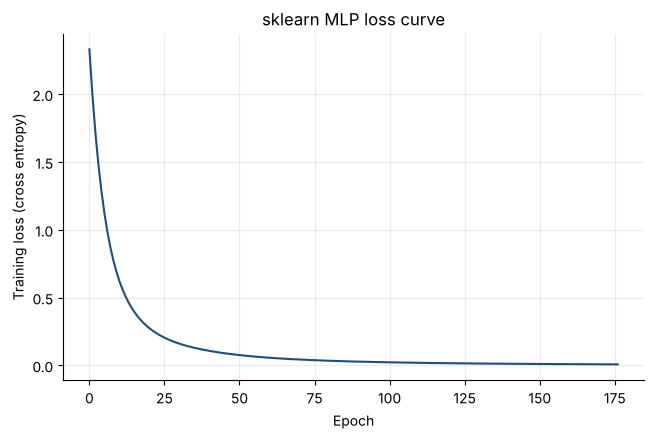

In [13]:
m = MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=300, random_state=SEED).fit(Xtr, y_train)
plt.plot(m.loss_curve_); plt.xlabel("Epoch"); plt.ylabel("Training loss (cross entropy)"); plt.title("sklearn MLP loss curve"); plt.show()

### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Change the metric used for model choice and see whether the chosen value changes.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

The tabular benchmark of Grinsztajn et al. does not apply to images, so we make no claim about it here. Our seed experiment illustrates why single run neural network results should be reported with a spread.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Use convolutional networks for larger images, tune the learning rate, and report several seeds.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- A hidden layer adds nonlinearity.
- Backpropagation is the chain rule.
- Report several seeds.

**Use cases.** Images, audio, text, and as a flexible baseline.

**Limitations.** Non convex, seed dependent.

**Recommended next notebook.** Unsupervised learning: K-Means.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.